# LAB | Hyperparameter Tuning

**Load the data**

Finally step in order to maximize the performance on your Spaceship Titanic model.

The data can be found here:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv

Metadata

https://github.com/data-bootcamp-v4/data/blob/main/spaceship_titanic.md

So far we've been training and evaluating models with default values for hyperparameters.

Today we will perform the same feature engineering as before, and then compare the best working models you got so far, but now fine tuning it's hyperparameters.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv"

spaceship = pd.read_csv(url)

print("Dataset loaded successfully")
print("Dataset shape:", spaceship.shape)

spaceship.head()

Dataset loaded successfully
Dataset shape: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


Now perform the same as before:
- Feature Scaling
- Feature Selection


In [3]:
# Separate the target from the predictors.
X = spaceship.drop(columns="Transported")
y = spaceship["Transported"].astype(int)

# Feature selection: remove identifiers and high-cardinality text fields.
# Cabin is retained in a more useful form by extracting deck and side.
X = X.copy()
X["CabinDeck"] = X["Cabin"].str.split("/").str[0]
X["CabinSide"] = X["Cabin"].str.split("/").str[2]
X = X.drop(columns=["PassengerId", "Name", "Cabin"])

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Stratification keeps the target proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Training shape: (6954, 12)
Test shape: (1739, 12)
Numerical features: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
Categorical features: ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'CabinDeck', 'CabinSide']


- Now let's use the best model we got so far in order to see how it can improve when we fine tune it's hyperparameters.

In [4]:
# Build one pipeline so preprocessing is fitted only on training data.
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ))
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

- Evaluate your model

Baseline Random Forest accuracy: 0.8033

Classification report:

                 precision    recall  f1-score   support

Not transported       0.78      0.84      0.81       863
    Transported       0.83      0.77      0.80       876

       accuracy                           0.80      1739
      macro avg       0.81      0.80      0.80      1739
   weighted avg       0.81      0.80      0.80      1739



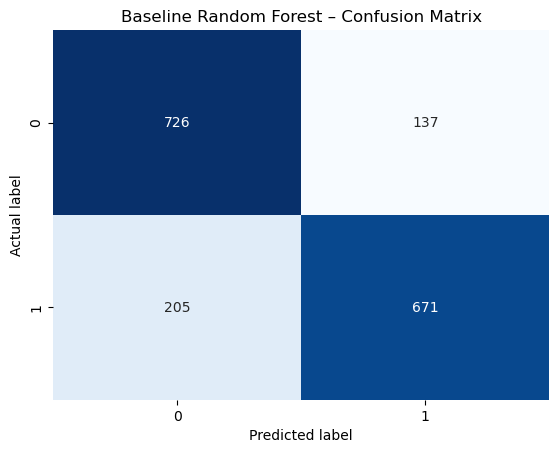

In [5]:
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Baseline Random Forest accuracy: {baseline_accuracy:.4f}")
print("\nClassification report:\n")
print(classification_report(y_test, baseline_predictions, target_names=["Not transported", "Transported"]))

baseline_cm = confusion_matrix(y_test, baseline_predictions)
sns.heatmap(baseline_cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Baseline Random Forest – Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

**Grid/Random Search**

For this lab we will use Grid Search.

- Define hyperparameters to fine tune.

In [6]:
# Parameter names use classifier__ because the model is inside a pipeline.
parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", "log2"]
}

print("Number of combinations:", np.prod([len(values) for values in parameter_grid.values()]))

Number of combinations: 48


- Run Grid Search

In [7]:
grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=parameter_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print(f"Best mean cross-validation accuracy: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best hyperparameters: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best mean cross-validation accuracy: 0.8004


- Evaluate your model

Baseline test accuracy: 0.8033
Tuned test accuracy:    0.8016
Change: -0.17 percentage points

Classification report for tuned model:

                 precision    recall  f1-score   support

Not transported       0.79      0.81      0.80       863
    Transported       0.81      0.79      0.80       876

       accuracy                           0.80      1739
      macro avg       0.80      0.80      0.80      1739
   weighted avg       0.80      0.80      0.80      1739



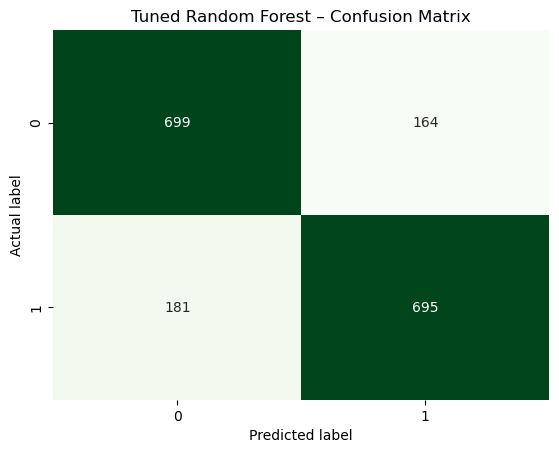

In [8]:
tuned_model = grid_search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Tuned test accuracy:    {tuned_accuracy:.4f}")
print(f"Change: {(tuned_accuracy - baseline_accuracy) * 100:+.2f} percentage points")
print("\nClassification report for tuned model:\n")
print(classification_report(y_test, tuned_predictions, target_names=["Not transported", "Transported"]))

tuned_cm = confusion_matrix(y_test, tuned_predictions)
sns.heatmap(tuned_cm, annot=True, fmt="d", cmap="Greens", cbar=False)
plt.title("Tuned Random Forest – Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()